# DATA 620 - Assignment 5

## Data

Davis Southern Women dataset from a 1941 sociology study, 18 women and 14 social events with an edge meaning a woman showed up to that event. Its a bipartite network, so two different kinds of nodes, and edges only ever go between the two types, never within one type. 

link : https://youtu.be/HAtSJVUrIo0

## Question

What can we figure out about 
(1) how the women relate to each other
(2) how the events relate to each other


## Setup

In [1]:
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from networkx.algorithms.community import greedy_modularity_communities

## Loading the data

In [11]:
G = nx.davis_southern_women_graph()
women, events = nx.bipartite.sets(G)
women = sorted(women)
events = sorted(events, key=lambda e: int(e[1:]))

print("Women  :", len(women), "Events :", len(events), "Edges  :", G.number_of_edges())

Women  : 18 Events : 14 Edges  : 89


## Projecting

Since there are no edges between events or edges between women we'd have to use the edges between women and events as a proxy to their relationship with other women and other events.Wr project this into two seperate graphs and can use edge weights that denote a count ofthe shared nodes. 
Women network: two women get linked if they went to at least one event together and the weight is how many events they shared
Events network: two events get linked if they shared at least one attendee weighted by how many women overlap

In [12]:
women_graph = nx.bipartite.weighted_projected_graph(G, women)
event_graph = nx.bipartite.weighted_projected_graph(G, events)

print("Women network : nodes:", women_graph.number_of_nodes(), " edges:", women_graph.number_of_edges())
print("Events network : nodes:", event_graph.number_of_nodes(), " edges:", event_graph.number_of_edges())

Women network : nodes: 18  edges: 139
Events network : nodes: 14  edges: 66


The women network is basically fully connected. 139 out of a possible 153 edges so almost every pair of women shared an event at some point. That tells me this isnt a bunch of separate little groups, its really one big overlapping social circle but ofcourse with with some pairs way closer than others. The events network is more spread out. 66 out of 91 possible so some events just didnt share anybody.

## Finding the most central women

In [13]:
degree = dict(women_graph.degree(weight="weight"))
eigenvector = nx.eigenvector_centrality(women_graph, weight="weight", max_iter=1000)

top_degree = sorted(degree.items(), key=lambda x: -x[1])[:5]
top_eigen = sorted(eigenvector.items(), key=lambda x: -x[1])[:5]

print("Top 5 : weighted degree:")
for name, val in top_degree:
    print(f"  {name:<20} {val}")

print("\nTop 5 : eigenvector centrality:")
for name, val in top_eigen:
    print(f"  {name:<20} {val:.3f}")

Top 5 : weighted degree:
  Theresa Anderson     57
  Evelyn Jefferson     50
  Brenda Rogers        46
  Sylvia Avondale      46
  Laura Mandeville     45

Top 5 : eigenvector centrality:
  Theresa Anderson     0.354
  Evelyn Jefferson     0.319
  Brenda Rogers        0.304
  Laura Mandeville     0.300
  Sylvia Avondale      0.273


Theresa Anderson and Evelyn Jefferson are at the top of both lists so it is not just that they went to a ton of events, they went to events with a lot of other well connected women. Degree just tells you someone is active, eigenvector is telling you they are actually sitting in the middle of the important part of the network.

## Are there any women groupings 

In [5]:
communities = list(greedy_modularity_communities(women_graph, weight="weight"))

for i, group in enumerate(communities):
    print(f"Group {i + 1} ({len(group)} women): {sorted(group)}")

Group 1 (10 women): ['Dorothy Murchison', 'Flora Price', 'Helen Lloyd', 'Katherina Rogers', 'Myra Liddel', 'Nora Fayette', 'Olivia Carleton', 'Pearl Oglethorpe', 'Sylvia Avondale', 'Verne Sanderson']
Group 2 (8 women): ['Brenda Rogers', 'Charlotte McDowd', 'Eleanor Nye', 'Evelyn Jefferson', 'Frances Anderson', 'Laura Mandeville', 'Ruth DeSand', 'Theresa Anderson']


So a greedy modularity algo splits the 18 women into two groups. 10 in one and 8 in the other which is kind of interesting given how dense the overall network is. If everyone was more or less equally connected to everyone else I didnt expect any real grouping. This means that there really is some kind of structure here. Like two social circles that overlap a lot but are not actually the same group. 

## PLotting the womens network with the grouping 

Node size is weighted degree ,edge thickness is common events between them 

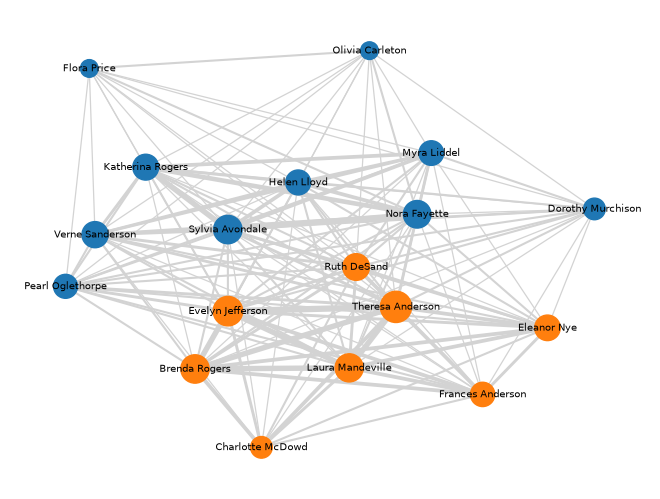

In [22]:
group_lookup = {name: i for i, group in enumerate(communities) for name in group}
colors = ["tab:blue" if group_lookup[n] == 0 else "tab:orange" for n in women_graph.nodes()]
sizes = [50 + 8 * degree[n] for n in women_graph.nodes()]
widths = [0.3 + 0.6 * women_graph[u][v]["weight"] for u, v in women_graph.edges()]

pos = nx.spring_layout(women_graph, weight="weight", seed=123, k=0.6)

nx.draw(women_graph, pos, node_color=colors, node_size=sizes, with_labels=True,
        font_size=7, edge_color="lightgray", width=widths)
plt.show()

The plot shows the two groups split out visually with the colors.As we can see the edges are thicker within the groups.But there also still seems to be a lot of connections between the group showing us that despite the grouping this is still a pretty dense graph 

## The main events

In [18]:
event_degree = dict(event_graph.degree(weight="weight"))
top_events = sorted(event_degree.items(), key=lambda x: -x[1])[:5]

print("Top 5 events by weighted degree :")
for name, val in top_events:
    print(f"  {name:<10} {val}")

attendance = {e: G.degree(e) for e in events}
print("\nAttendance count per event:")
for e in events:
    print(f"  {e:<10} {attendance[e]} people")

Top 5 events by weighted degree :
  E8         59
  E7         48
  E9         46
  E6         41
  E5         38

Attendance count per event:
  E1         3 people
  E2         3 people
  E3         6 people
  E4         4 people
  E5         8 people
  E6         8 people
  E7         10 people
  E8         14 people
  E9         12 people
  E10        5 people
  E11        4 people
  E12        6 people
  E13        3 people
  E14        3 people


The events with the most people are also the ones most tied into other events in the projection. Kinda makes sense that a popular event is just more likely to overlap with other events. A few big events seems to have acted as hubs holding the whole community together while the smaller ones were really just for a narrower slice of the group.

## Finding the bridges between the groups

In [8]:
betweenness = nx.betweenness_centrality(women_graph, weight="weight")

bridge_df = pd.DataFrame({"betweenness": betweenness, "degree": degree})
bridge_df["group"] = bridge_df.index.map(group_lookup)
bridge_df["degree_rank"] = bridge_df["degree"].rank(ascending=False)
bridge_df["betweenness_rank"] = bridge_df["betweenness"].rank(ascending=False)
bridge_df["rank_gap"] = bridge_df["degree_rank"] - bridge_df["betweenness_rank"]

print("Top 5 by betweenness centrality:")
print(bridge_df.sort_values("betweenness", ascending=False)[["betweenness", "degree", "group"]].head(5))

Top 5 by betweenness centrality:
                   betweenness  degree  group
Olivia Carleton       0.136285      14      0
Flora Price           0.136285      14      0
Dorothy Murchison     0.095770      24      0
Helen Lloyd           0.061689      34      0
Frances Anderson      0.057861      32      1


So this gives us kind of a different angle than just degree. I was curious to find out about the people connecting people between the groups. Olivia and Flora actually have the lowest degree out of the top 5 with only 14 each way less than Helen or Frances. But they blow everyone away on betweenness. That means they arent the most social in general but theyre cruscial to connecting parts of the network that otherwise wouldnt be linked. Dorothy is similar, lower degree but still punching above her weight on betweenness. All three of these bridge women are in the same group though which is interesting.

## Do events match the two groups

In [19]:
event_communities = list(greedy_modularity_communities(event_graph, weight="weight"))
print(f"Event network : {len(event_communities)} groups:")
for i, group in enumerate(event_communities):
    print(f"  Group {i + 1}: {sorted(group, key=lambda e: int(e[1:]))}")

print("\nAttendee per event by womens group:")
for e in events:
    attendees = [w for w in women if G.has_edge(w, e)]
    group_counts = {0: 0, 1: 0}
    for w in attendees:
        group_counts[group_lookup[w]] += 1
    print(f"  {e:<4} total={len(attendees):<2} group1={group_counts[0]:<2} group2={group_counts[1]}")

Event network : 2 groups:
  Group 1: ['E1', 'E2', 'E3', 'E4', 'E5', 'E6', 'E7', 'E8']
  Group 2: ['E9', 'E10', 'E11', 'E12', 'E13', 'E14']

Attendee per event by womens group:
  E1   total=3  group1=0  group2=3
  E2   total=3  group1=0  group2=3
  E3   total=6  group1=0  group2=6
  E4   total=4  group1=0  group2=4
  E5   total=8  group1=0  group2=8
  E6   total=8  group1=2  group2=6
  E7   total=10 group1=4  group2=6
  E8   total=14 group1=7  group2=7
  E9   total=12 group1=9  group2=3
  E10  total=5  group1=5  group2=0
  E11  total=4  group1=4  group2=0
  E12  total=6  group1=6  group2=0
  E13  total=3  group1=3  group2=0
  E14  total=3  group1=3  group2=0


So E1 through E5 are attended only by group 2 not a single group 1 woman shows up. Then E10 through E14 si the opposite, only group 1 attendees. E6 through E9 is the zone where both groups start showing up together and E8 lands on an exact 7 and 7 split. The numbering of the events seem to track from one group to mixed to the other group. 

## Summary

- The raw data is bipartite women and events never connect directly so the analysis can only be done after projecting it into two separate one mode networks
- Women projection ends up almost fully connected so its really one overlapping social world not isolated cliques
- Even with all that density community detection still splits the women into two groups of 10 and 8
- Theresa and Evelyn come out on top for both degree and eigenvector centrality so theyre not just active theyre a core part of the network
- Olivia and Flora have way lower degree but the highest betweenness by far making them the real bridges holding the two groups together
- On the events side the biggest events are also the most central ones in the projection basically acting as hubs for the whole community
- Event communities split almost perfectly into E1-E8 and E9-E14, and that lines up with the two women groups.
- E6 through E9 is the overlap zone with E8 landing on an exact 7-7 split between both groups